# Customer Churn Prediction – Telco Dataset
Course: Artificial Intelligence | Assignment 1

## Step 0: Importing the libraries

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report,
                             roc_auc_score, ConfusionMatrixDisplay)

sns.set_style("whitegrid")

## Step 1: Load and understand the data

In [7]:
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn (1) (1).csv")

print("Shape of dataset:", df.shape)
print("\nColumn names:\n", list(df.columns))
df.head()

Shape of dataset: (7043, 21)

Column names:
 ['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [9]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.0,0.00,0.00,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.0,29.00,55.00,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.5,70.35,89.85,118.75


In [10]:
churn_counts = df["Churn"].value_counts()
churn_share = df["Churn"].value_counts(normalize=True).mul(100).round(2)
pd.DataFrame({"Customers": churn_counts, "Percent (%)": churn_share})

,Customers,Percent (%)
Churn,,
No,5174,73.46
Yes,1869,26.54


## Step 2: Data cleaning

In [11]:

print("Missing values in each column:\n", df.isna().sum()[df.isna().sum() > 0])
print("Total missing cells:", df.isna().sum().sum())
print("Duplicate customers:", df.duplicated().sum())

Missing values in each column:
 Series([], dtype: int64)
Total missing cells: 0
Duplicate customers: 0


In [12]:

blank_rows = df[df["TotalCharges"].str.strip() == ""]
print("Blank TotalCharges rows:", len(blank_rows))
blank_rows[["customerID", "tenure", "MonthlyCharges", "TotalCharges"]]

Blank TotalCharges rows: 11


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,
753,3115-CZMZD,0,20.25,
936,5709-LVOEQ,0,80.85,
1082,4367-NUYAO,0,25.75,
1340,1371-DWPAZ,0,56.05,
3331,7644-OMVMY,0,19.85,
3826,3213-VVOLG,0,25.35,
4380,2520-SGTTA,0,20.00,
5218,2923-ARZLG,0,19.70,
6670,4075-WKNIU,0,73.35,


In [13]:

df["TotalCharges"] = pd.to_numeric(df["TotalCharges"].replace(" ", np.nan))
df["TotalCharges"] = df["TotalCharges"].fillna(df["MonthlyCharges"] * df["tenure"])

df["SeniorCitizen"] = df["SeniorCitizen"].map({1: "Yes", 0: "No"})
df.drop(columns="customerID", inplace=True)

print("TotalCharges type now:", df["TotalCharges"].dtype)
print("Missing values left:", df.isna().sum().sum())
print("Final shape:", df.shape)

TotalCharges type now: float64
Missing values left: 0
Final shape: (7043, 20)


## Step 3: Exploratory Data Analysis

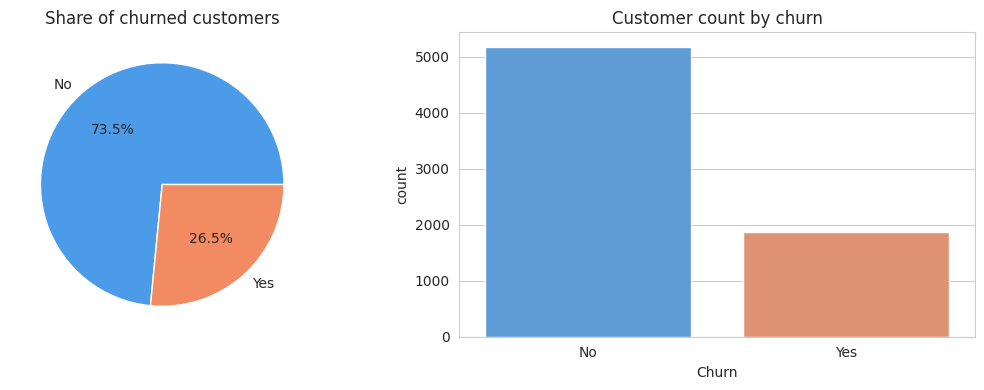

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
df["Churn"].value_counts().plot.pie(autopct="%1.1f%%", colors=["#4c9be8", "#f28b62"], ax=ax[0])
ax[0].set_ylabel("")
ax[0].set_title("Share of churned customers")
sns.countplot(data=df, x="Churn", hue="Churn", palette=["#4c9be8", "#f28b62"], legend=False, ax=ax[1])
ax[1].set_title("Customer count by churn")
plt.tight_layout()
plt.show()

In [15]:
def churn_table(column):
    t = pd.crosstab(df[column], df["Churn"], normalize="index").mul(100).round(1)
    return t.sort_values("Yes", ascending=False)

for c in ["Contract", "InternetService", "PaymentMethod", "TechSupport", "SeniorCitizen"]:
    print(churn_table(c), "\n")

Churn             No   Yes
Contract                  
Month-to-month  57.3  42.7
One year        88.7  11.3
Two year        97.2   2.8 

Churn              No   Yes
InternetService            
Fiber optic      58.1  41.9
DSL              81.0  19.0
No               92.6   7.4 

Churn                        No   Yes
PaymentMethod                        
Electronic check           54.7  45.3
Mailed check               80.9  19.1
Bank transfer (automatic)  83.3  16.7
Credit card (automatic)    84.8  15.2 

Churn                  No   Yes
TechSupport                    
No                   58.4  41.6
Yes                  84.8  15.2
No internet service  92.6   7.4 

Churn            No   Yes
SeniorCitizen            
Yes            58.3  41.7
No             76.4  23.6 



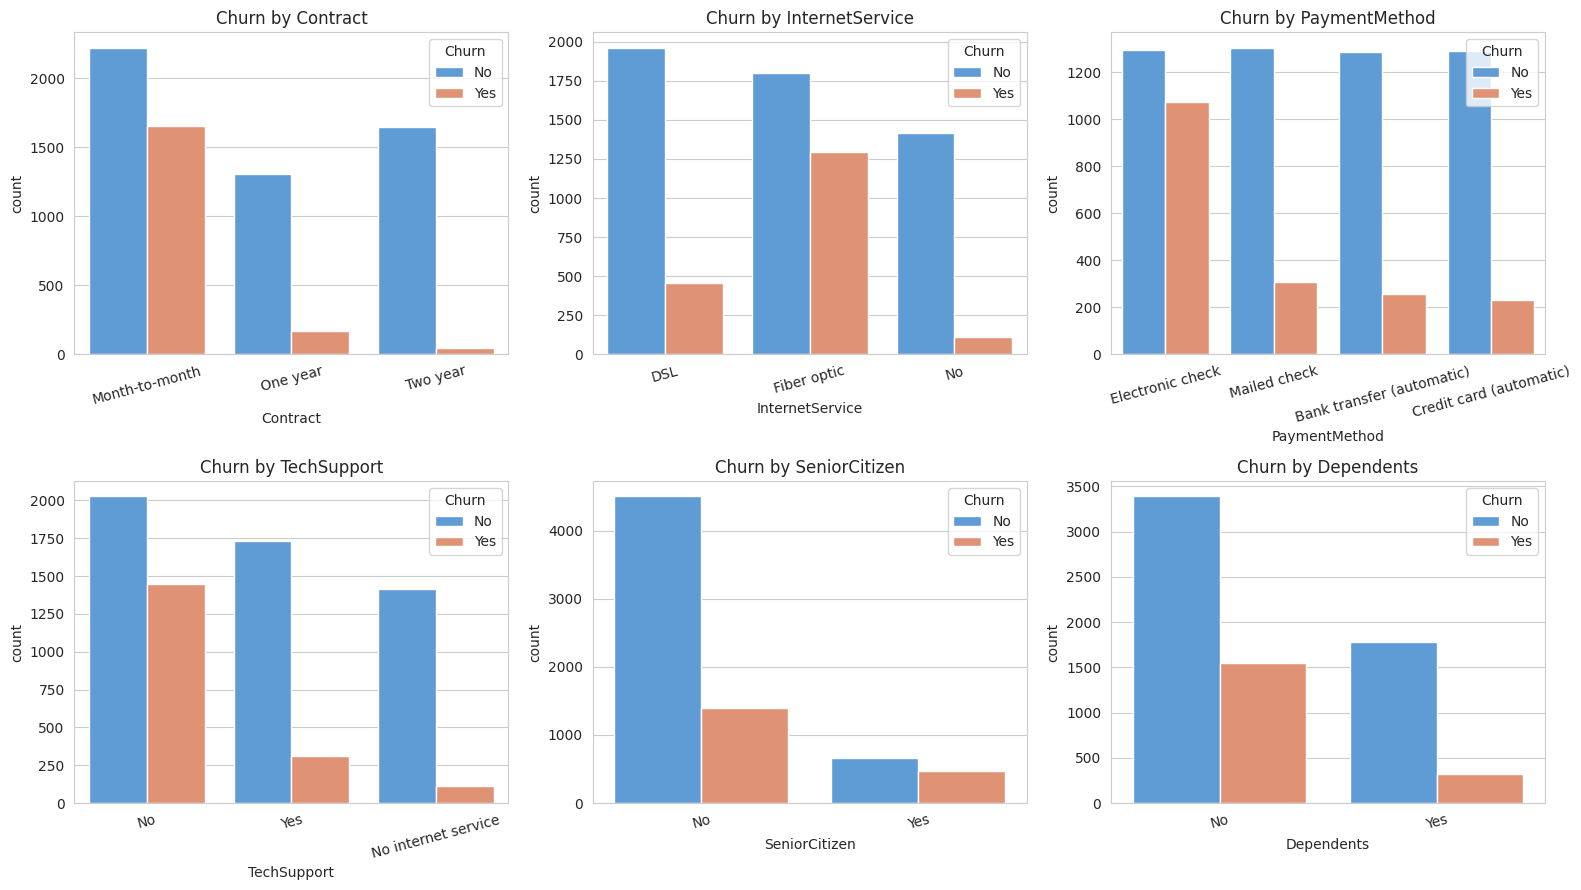

In [16]:
cat_cols = ["Contract", "InternetService", "PaymentMethod", "TechSupport", "SeniorCitizen", "Dependents"]
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, c in zip(axes.flat, cat_cols):
    sns.countplot(data=df, x=c, hue="Churn", palette=["#4c9be8", "#f28b62"], ax=ax)
    ax.set_title("Churn by " + c)
    ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

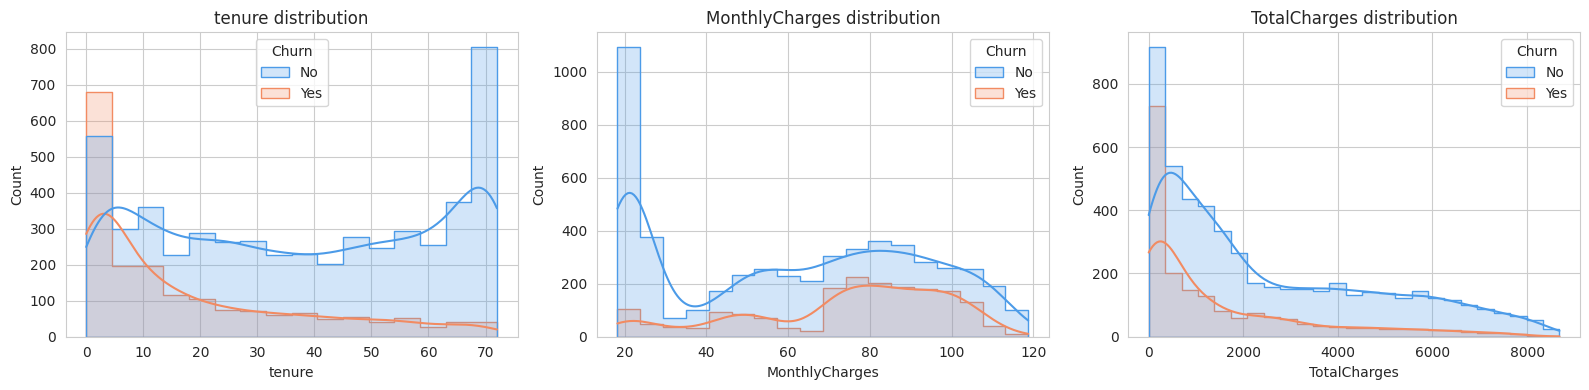

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, c in zip(axes, ["tenure", "MonthlyCharges", "TotalCharges"]):
    sns.histplot(data=df, x=c, hue="Churn", kde=True, element="step",
                 palette=["#4c9be8", "#f28b62"], ax=ax)
    ax.set_title(c + " distribution")
plt.tight_layout()
plt.show()

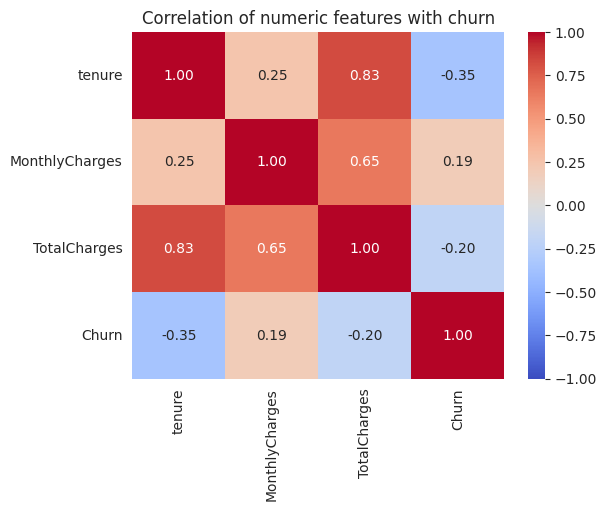

In [18]:
num_df = df[["tenure", "MonthlyCharges", "TotalCharges"]].copy()
num_df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})
plt.figure(figsize=(6, 4.5))
sns.heatmap(num_df.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation of numeric features with churn")
plt.show()

## Step 4: Feature engineering and encoding

In [19]:
services = ["PhoneService", "MultipleLines", "OnlineSecurity", "OnlineBackup",
            "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]

def build_features(frame):
    f = frame.copy()
    f = f.replace({"No internet service": "No", "No phone service": "No"})

    f["TotalServices"] = (f[services] == "Yes").sum(axis=1)
    f["AvgMonthlySpend"] = np.where(f["tenure"] > 0, f["TotalCharges"] / f["tenure"], f["MonthlyCharges"])
    f["TenureGroup"] = pd.cut(f["tenure"], bins=[-1, 12, 24, 48, 72],
                              labels=["0-1yr", "1-2yr", "2-4yr", "4-6yr"])
    f["AutoPay"] = f["PaymentMethod"].str.contains("automatic").astype(int)

    binary = [c for c in f.columns if set(f[c].unique()) <= {"Yes", "No"}]
    f[binary] = (f[binary] == "Yes").astype(int)
    f["gender"] = f["gender"].map({"Female": 0, "Male": 1})

    f = pd.get_dummies(f, columns=["InternetService", "Contract", "PaymentMethod", "TenureGroup"],
                       drop_first=True, dtype=int)
    return f

X = build_features(df.drop(columns="Churn"))
y = df["Churn"].map({"Yes": 1, "No": 0})

print("Features X:", X.shape)
print("Target y:", y.shape, "| churn rate:", round(y.mean() * 100, 2), "%")
X.head()

Features X: (7043, 29)
Target y: (7043,) | churn rate: 26.54 %


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,OnlineSecurity,OnlineBackup,DeviceProtection,...,InternetService_Fiber optic,InternetService_No,Contract_One year,Contract_Two year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,TenureGroup_1-2yr,TenureGroup_2-4yr,TenureGroup_4-6yr
0,0,0,1,0,1,0,0,0,1,0,...,0,0,0,0,0,1,0,0,0,0
1,1,0,0,0,34,1,0,1,0,1,...,0,0,1,0,0,0,1,0,1,0
2,1,0,0,0,2,1,0,1,1,0,...,0,0,0,0,0,0,1,0,0,0
3,1,0,0,0,45,0,0,1,0,1,...,0,0,1,0,0,0,0,0,1,0
4,0,0,0,0,2,1,0,0,0,0,...,1,0,0,0,0,1,0,0,0,0


## Step 5: Train / test split and model training

In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)
print("Train size:", X_train.shape[0], "| Test size:", X_test.shape[0])

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

Train size: 5634 | Test size: 1409


In [22]:
log_model = LogisticRegression(max_iter=2000, class_weight="balanced")
log_model.fit(X_train_sc, y_train)

rf_model = RandomForestClassifier(n_estimators=300, max_depth=10, min_samples_leaf=5,
                                  class_weight="balanced", random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)
print("Both models trained.")

Both models trained.


## Step 6: Model evaluation

===== Logistic Regression =====
              precision    recall  f1-score   support

    No Churn       0.91      0.71      0.80      1035
       Churn       0.50      0.79      0.61       374

    accuracy                           0.73      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.73      0.75      1409

===== Random Forest =====
              precision    recall  f1-score   support

    No Churn       0.90      0.77      0.83      1035
       Churn       0.54      0.75      0.63       374

    accuracy                           0.76      1409
   macro avg       0.72      0.76      0.73      1409
weighted avg       0.80      0.76      0.77      1409



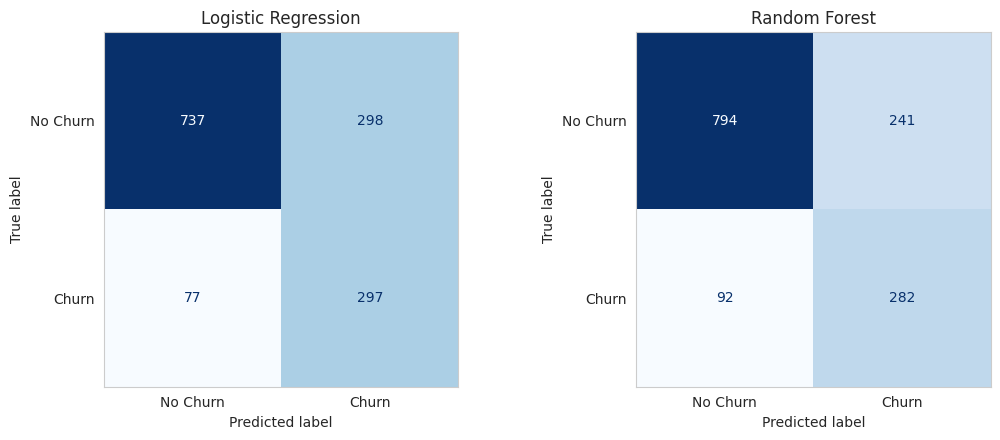

In [23]:
models = {
    "Logistic Regression": (log_model, X_test_sc),
    "Random Forest": (rf_model, X_test),
}

results = {}
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, (model, X_eval)) in zip(axes, models.items()):
    y_pred = model.predict(X_eval)
    y_prob = model.predict_proba(X_eval)[:, 1]
    results[name] = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
    }
    print("=====", name, "=====")
    print(classification_report(y_test, y_pred, target_names=["No Churn", "Churn"]))
    ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                           display_labels=["No Churn", "Churn"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
    ax.grid(False)
plt.tight_layout()
plt.show()

                     Accuracy  Precision  Recall  F1-Score  ROC-AUC
Logistic Regression    0.7339     0.4992  0.7941    0.6130   0.8417
Random Forest          0.7637     0.5392  0.7540    0.6288   0.8444


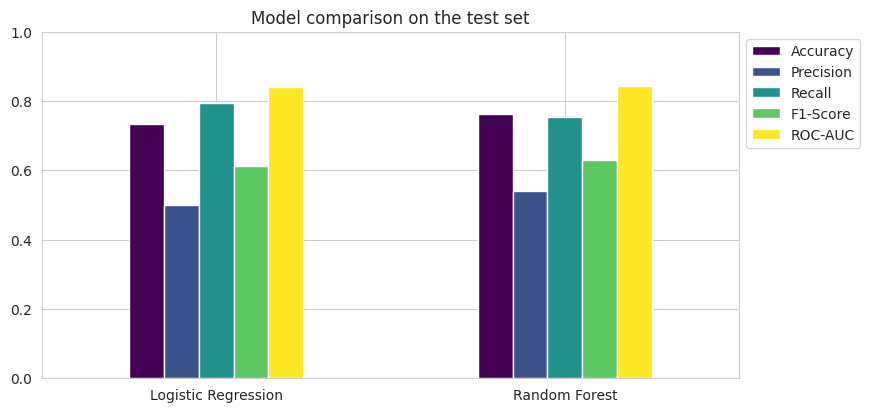

In [24]:
results_df = pd.DataFrame(results).T.round(4)
print(results_df)
results_df.plot(kind="bar", figsize=(9, 4.5), rot=0, colormap="viridis")
plt.title("Model comparison on the test set")
plt.ylim(0, 1)
plt.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

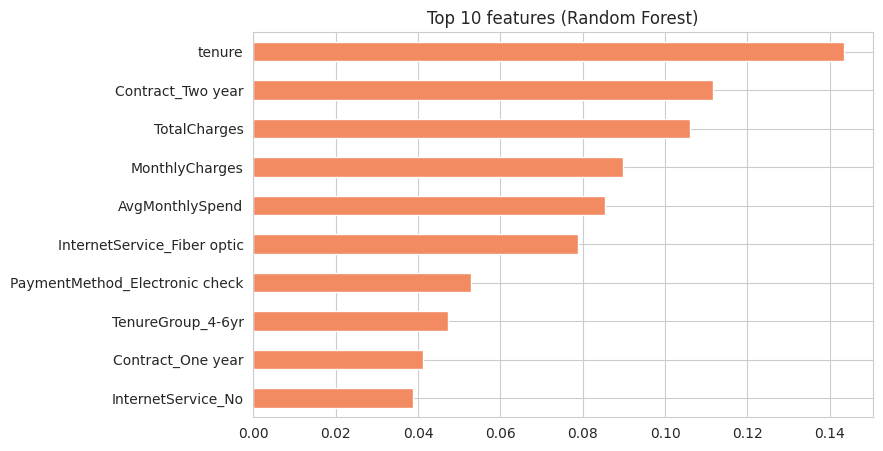

In [25]:
importance = pd.Series(rf_model.feature_importances_, index=X.columns).nlargest(10)
importance.sort_values().plot(kind="barh", color="#f28b62", figsize=(8, 5))
plt.title("Top 10 features (Random Forest)")
plt.show()

## Step 7: Predicting churn for new customers

In [26]:

final_model = rf_model

def predict_churn(customer):
    row = build_features(pd.DataFrame([customer]))
    row = row.reindex(columns=X.columns, fill_value=0)
    prob = final_model.predict_proba(row)[0, 1]
    label = "Churn" if prob >= 0.5 else "No Churn"
    return label, round(prob * 100, 1)

customer_1 = {"gender": "Female", "SeniorCitizen": "Yes", "Partner": "No", "Dependents": "No",
              "tenure": 2, "PhoneService": "Yes", "MultipleLines": "No",
              "InternetService": "Fiber optic", "OnlineSecurity": "No", "OnlineBackup": "No",
              "DeviceProtection": "No", "TechSupport": "No", "StreamingTV": "Yes",
              "StreamingMovies": "No", "Contract": "Month-to-month", "PaperlessBilling": "Yes",
              "PaymentMethod": "Electronic check", "MonthlyCharges": 85.5, "TotalCharges": 171.0}

customer_2 = {"gender": "Male", "SeniorCitizen": "No", "Partner": "Yes", "Dependents": "Yes",
              "tenure": 60, "PhoneService": "Yes", "MultipleLines": "Yes",
              "InternetService": "DSL", "OnlineSecurity": "Yes", "OnlineBackup": "Yes",
              "DeviceProtection": "Yes", "TechSupport": "Yes", "StreamingTV": "No",
              "StreamingMovies": "No", "Contract": "Two year", "PaperlessBilling": "No",
              "PaymentMethod": "Bank transfer (automatic)", "MonthlyCharges": 70.0, "TotalCharges": 4200.0}

for i, c in enumerate([customer_1, customer_2], start=1):
    label, prob = predict_churn(c)
    print(f"Customer {i}: {label}  (churn probability = {prob}%)")

Customer 1: Churn  (churn probability = 67.8%)
Customer 2: No Churn  (churn probability = 10.1%)


In [27]:

check = X_test.sample(8, random_state=1)
pd.DataFrame({
    "Actual": y_test.loc[check.index].map({1: "Churn", 0: "No Churn"}),
    "Predicted": np.where(final_model.predict(check) == 1, "Churn", "No Churn"),
    "Churn prob (%)": (final_model.predict_proba(check)[:, 1] * 100).round(1),
})

,Actual,Predicted,Churn prob (%)
126,Churn,Churn,67.1
4017,No Churn,No Churn,10.1
5860,Churn,Churn,77.1
4114,No Churn,No Churn,2.7
3790,Churn,No Churn,14.2
984,No Churn,No Churn,1.2
4408,No Churn,No Churn,5.9
2923,No Churn,No Churn,29.6
